# Cyclic Voltammetry Simulation with Soft Potato

This notebook shows how to perform a cyclic voltammetry (CV) simulation for a reversible (Nernstian) redox couple undergoing an oxidation ($R \rightleftharpoons O + n\text{e}^-$) and compare the peak current with the `randles_sevcik` function from the analytical module (`softpotato.analytical.voltammetry`). The goal is to show the full modelling workflow with Soft Potato:

1. **Pre-processing:** Define physical and electrochemical parameters ($n$, $D$, $c_{\text{bulk}}$, $v$, $E^{0\prime}$), build the spatial grid and triangular potential waveform sweeping anodically, calculate surface equilibrium concentrations with `nernst_equilibrium_concentrations`, and configure initial and boundary conditions for two species ($\text{O}$ and $\text{R}$) using `DiffusionProblem`.
2. **Solving:** Run the numerical simulation using the implicit Crank–Nicolson finite difference solver (`get_solver("crank_nicolson")`).
3. **Post-processing and verification:** Extract concentration profiles across the diffusion layer, plot the cyclic voltammogram ($I$ vs. $E$) starting in the positive (anodic) current regime, and benchmark the simulated anodic peak current and peak separation against the theoretical Randles–Ševčík response.


## Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from softpotato.solver import DiffusionProblem, DirichletBC, get_solver
from softpotato.analytical.kinetics import nernst_equilibrium_concentrations
from softpotato.analytical.voltammetry import randles_sevcik


## Pre-processing

In [2]:
# Parameters
n_electrons = 1

# Initialising the species:
D = 1e-5 # cm2/s
diffusivity = {
    "O": D,
    "R": D
}

# Concentrations (1 mM bulk solution of reduced species R)
cO_bulk = 0.0  # mol/cm3
cR_bulk = 1e-6 # mol/cm3
c_total = cO_bulk + cR_bulk

# Voltammetric waveform parameters:
E0 = 0.0       # V (formal potential)
v = 0.1        # V/s (scan rate)
E_start = -0.5 # V (starting potential, cathodic of E0)
E_rev = 0.5    # V (reversal potential, anodic of E0)

# Time parameters for triangular scan (sweeping positive first):
t_forward = abs(E_rev - E_start) / v
t_max = 2 * t_forward # s
t_span = (0, t_max)

def potential(t):
    """Applied electrode potential as a function of time (anodic forward sweep)."""
    if np.isscalar(t):
        return E_start + v * t if t <= t_forward else E_rev - v * (t - t_forward)
    t = np.asarray(t)
    return np.where(t <= t_forward, E_start + v * t, E_rev - v * (t - t_forward))

# Fast kinetics surface boundary conditions using Nernst equation:
# R <=> O + n e-
def cO_surface(t):
    E = potential(t)
    c_ox, _ = nernst_equilibrium_concentrations(E, c_total=c_total, E0=E0, n=n_electrons)
    return c_ox

def cR_surface(t):
    E = potential(t)
    _, c_red = nernst_equilibrium_concentrations(E, c_total=c_total, E0=E0, n=n_electrons)
    return c_red

# Building the grid:
x_max = 6 * np.sqrt(D * t_max) # cm (~0.066 cm)
x_n = 201                      # number of space points
grid = np.linspace(0, x_max, x_n)

# Setting the initial conditions:
initial_conditions = {
    "O": cO_bulk,
    "R": cR_bulk
}

# Setting the boundary conditions:
boundary_conditions = {
    "O": (DirichletBC(cO_surface), DirichletBC(cO_bulk)),
    "R": (DirichletBC(cR_surface), DirichletBC(cR_bulk)),
}


In [3]:
# Build the problem
problem = DiffusionProblem(
    n_electrons = n_electrons,
    diffusivity = diffusivity,
    grid = grid,
    initial_conditions = initial_conditions,
    boundary_conditions = boundary_conditions
)


## Solving

In [4]:
# Run the simulation:
solver = get_solver("crank_nicolson", dt=0.01)
result = solver.solve(problem, t_span=t_span)


## Post-processing and verification

In [5]:
# Extract values
c_O = result["O"]
c_R = result["R"]
I = result.currents["O"]
t = result.t
x = result.x
E = potential(t)


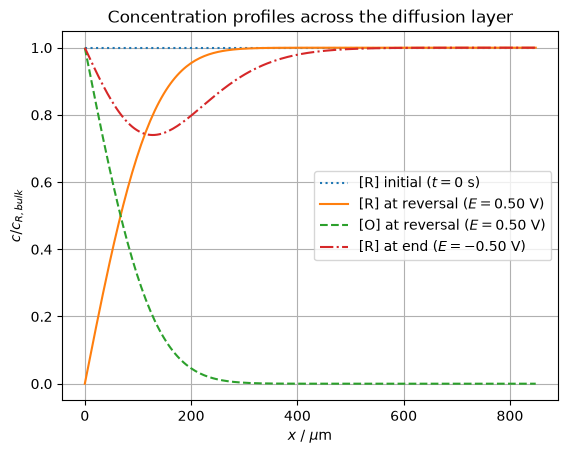

In [6]:
# Plot concentration profiles at key points during the scan:
idx_rev = np.argmin(np.abs(t - t_forward))

plt.figure()
plt.plot(x * 1e4, c_R[0, :] / cR_bulk, ":", label="[R] initial ($t = 0$ s)")
plt.plot(x * 1e4, c_R[idx_rev, :] / cR_bulk, "-", label=f"[R] at reversal ($E = {E[idx_rev]:.2f}$ V)")
plt.plot(x * 1e4, c_O[idx_rev, :] / cR_bulk, "--", label=f"[O] at reversal ($E = {E[idx_rev]:.2f}$ V)")
plt.plot(x * 1e4, c_R[-1, :] / cR_bulk, "-.", label=f"[R] at end ($E = {E[-1]:.2f}$ V)")
plt.xlabel(r"$x$ / $\mu$m")
plt.ylabel(r"$c / c_{R,bulk}$")
plt.title("Concentration profiles across the diffusion layer")
plt.grid()
plt.legend()
plt.show()


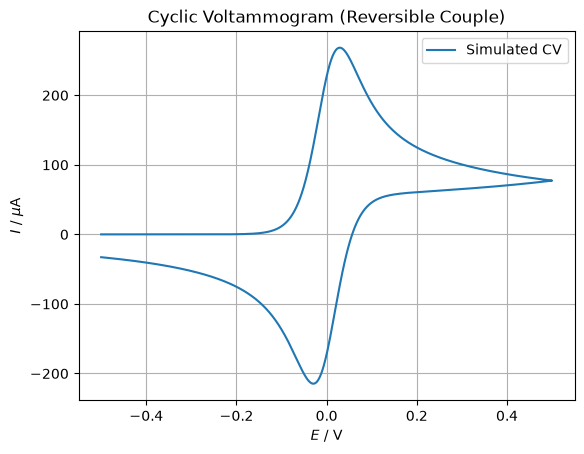

In [7]:
# Plot the Cyclic Voltammogram (I vs. E)
plt.figure()
plt.plot(E, I * 1e6, label="Simulated CV")
plt.xlabel("$E$ / V")
plt.ylabel(r"$I$ / $\mu$A")
plt.title("Cyclic Voltammogram (Reversible Couple)")
plt.grid()
plt.legend()
plt.show()


In [8]:
# Use randles_sevcik() from the analytical module to compare with the simulation:
area = problem.geometry.area
Ip_analytical = randles_sevcik(
    v=v,
    c_bulk=cR_bulk,
    D=D,
    area=area,
    n=n_electrons,
    scan_direction="anodic"
)

# Extract simulated anodic (forward) and cathodic (reverse) peaks:
idx_fwd = t <= t_forward
idx_pa = np.argmax(I[idx_fwd])
Ip_simulated = I[idx_pa]
Ep_simulated = E[idx_pa]

idx_rev_arr = np.where(t >= t_forward)[0]
idx_pc_local = np.argmin(I[idx_rev_arr])
idx_pc = idx_rev_arr[idx_pc_local]
Ip_cathodic = I[idx_pc]
Ep_cathodic = E[idx_pc]

relative_error = abs(Ip_simulated - Ip_analytical) / abs(Ip_analytical) * 100
delta_Ep = abs(Ep_simulated - Ep_cathodic) * 1000

print(f"Analytical peak current (Randles-Sevcik): {Ip_analytical * 1e6:.2f} uA")
print(f"Simulated anodic peak current:           {Ip_simulated * 1e6:.2f} uA")
print(f"Anodic peak potential (Ep,a):            {Ep_simulated * 1e3:.1f} mV")
print(f"Cathodic peak potential (Ep,c):          {Ep_cathodic * 1e3:.1f} mV")
print(f"Peak separation (Delta Ep):              {delta_Ep:.1f} mV (theoretical ~ 57.0 mV at 25 °C)")
print(f"Peak current error:                      {relative_error:.3f}%")


Analytical peak current (Randles-Sevcik): 268.65 uA
Simulated anodic peak current:           268.42 uA
Anodic peak potential (Ep,a):            29.0 mV
Cathodic peak potential (Ep,c):          -29.0 mV
Peak separation (Delta Ep):              58.0 mV (theoretical ~ 57.0 mV at 25 °C)
Peak current error:                      0.084%
